# 01 — BERT Sequence Classification & Evaluation

## Objective
Understand how a pretrained BERT model performs sequence classification using the Stanford Sentiment Treebank (SST-2) dataset. Explore tokenization, logits, probability distributions, class predictions, evaluation metrics, and confusion matrix analysis. Investigate high-confidence misclassifications to understand the model's limitations.

### Install required dependencies

In [ ]:
%pip install torch transformers datasets pandas scikit-learn matplotlib seaborn

### Load Stanford Sentiment Treebank dataset

In [ ]:
from datasets import load_dataset

dataset = load_dataset("nyu-mll/glue", "sst2")

print(dataset)

### Read first 10 validation headers

In [ ]:
df = dataset["validation"].to_pandas()

print(df.head(10))

### Check data before running the model, etc. sample size, class distribution, missing values and text lengths

In [ ]:
print("Examples count:", len(df))

print("\nClass count:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentences length:")
print(df["sentence"].str.split().str.len().describe())

### Run a BERT model on whole validation dataset

In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

model_name = "textattack/bert-base-uncased-SST-2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    attn_implementation="sdpa"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

### Prepare prediction with batches pipeline approach

In [8]:
from torch.utils.data import DataLoader
import numpy as np

sentences = dataset["validation"]["sentence"]
true_labels = np.array(dataset["validation"]["label"])

BATCH_SIZE = 16

loader = DataLoader(
    sentences,
    batch_size=BATCH_SIZE,
    shuffle=False
)

all_logits = []

model.eval()

with torch.inference_mode():
    for batch in loader:
        inputs = tokenizer(
            list(batch),
            padding=True,
            truncation=True,
            return_tensors="pt"
        ).to(device)

        outputs = model(**inputs)

        all_logits.append(outputs.logits.cpu())

logits = torch.cat(all_logits, dim=0)

probabilities = torch.softmax(logits, dim=-1)
predictions = probabilities.argmax(dim=-1).numpy()
confidences = probabilities.max(dim=-1).values.numpy()

### Evaluate model with true labels and show an evaluation metrics using dedicated visualizations for appropriate metric type
- We assume that the label `1` is a **positive** class

Accuracy: 0.9243119266055045
Precision: 0.918141592920354
Recall: 0.9346846846846847


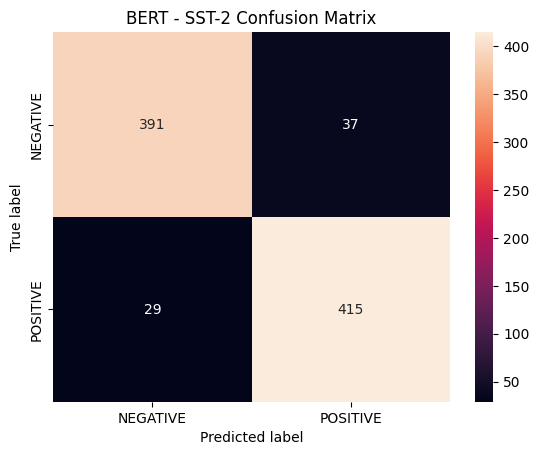

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(true_labels, predictions))

print("Precision:", precision_score(true_labels, predictions))

print("Recall:", recall_score(true_labels, predictions))

cm = confusion_matrix(true_labels, predictions)

sns.heatmap(
    cm, 
    annot=True,
    fmt="d",
    xticklabels=["NEGATIVE", "POSITIVE"],
    yticklabels=["NEGATIVE", "POSITIVE"]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("BERT - SST-2 Confusion Matrix")
plt.show()

### Analyze model errors 

In [10]:
import pandas as pd

results = pd.DataFrame({
    "sentence": sentences,
    "true_label": true_labels,
    "predicted_label": predictions,
    "confidence": confidences
})

errors = results[
    results["true_label"] != results["predicted_label"]
]

top_errors = errors.sort_values(
    "confidence",
    ascending=False
).head(20)

print(
    top_errors[
        ["sentence", "true_label", "predicted_label", "confidence"]
    ].to_string(index=False)
)

false_positive = errors[
    (errors["true_label"] == 0) &
    (errors["predicted_label"] == 1)
]

false_negative = errors[
    (errors["true_label"] == 1) &
    (errors["predicted_label"] == 0)
]

print("False Positive:", len(false_positive))
print("False Negative:", len(false_negative))

                                                                                                                                                                                                 sentence  true_label  predicted_label  confidence
                                                                                                                                               the lower your expectations , the more you 'll enjoy it .            0                1    0.999311
                                                                                                                  moretti 's compelling anatomy of grief and the difficult process of adapting to loss .            0                1    0.999199
                                                       this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms .            0                1    0.999096
                            

### Error Analysis
An analysis of the 20 incorrect predictions with the highest confidence levels showed that the BERT model can assign very high probabilities (above 99%) to **incorrect classes**.

Among the examples analyzed, <b style="color:red">14</b> were cases of `negative opinions` being **misclassified as positive**, while 6 involved the opposite situation.
A qualitative analysis suggests that potential sources of error may include:
- irony and indirectly expressed criticism;
- negation and contrasting constructions;
- mixed sentiment within a single sentence;
- ambiguity in the interpretation of certain parts of reviews.

The results also indicate that a high softmax probability does not guarantee correct classification. A potential direction for further experiments could be an analysis of the model’s calibration.

**Final conclusion**: The model achieves high overall performance (92.43% accuracy), but an analysis of individual cases reveals limitations that are not apparent in aggregated classification metrics.